In [1]:
import pandas as pd
import numpy as np

print("🛡️ UPI Shield AI starting...")

rng = np.random.default_rng(42)

# Generate synthetic transaction data
n = 300
rows = []

for i in range(n):
    suspicious = int(i % 10 == 0 or i % 17 == 0)

    if suspicious:
        amount = float(rng.integers(8000, 35000))
        typical_amount = float(rng.integers(500, 2500))
        tx_count_10m = int(rng.integers(5, 10))
        new_payee = int(rng.integers(0, 2))
    else:
        typical_amount = float(rng.integers(500, 4000))
        amount = float(max(
            100, rng.normal(typical_amount, typical_amount * 0.35)
        ))
        tx_count_10m = int(rng.integers(1, 4))
        new_payee = int(rng.random() < 0.15)

    rows.append({
        "transaction_id": f"TX-{i+1:04d}",
        "amount": round(amount, 2),
        "typical_amount": round(typical_amount, 2),
        "tx_count_10m": tx_count_10m,
        "new_payee": new_payee,
        "label": suspicious
    })

df = pd.DataFrame(rows)

print("Dataset created successfully!")
print("Total transactions:", len(df))
display(df.head(10))

🛡️ UPI Shield AI starting...
Dataset created successfully!
Total transactions: 300


,transaction_id,amount,typical_amount,tx_count_10m,new_payee,label
0,TX-0001,10409.00,2047.0,8,0,1
1,TX-0002,2678.33,2015.0,3,1,0
2,TX-0003,2446.79,2342.0,3,0,0
3,TX-0004,1610.49,2296.0,1,0,0
4,TX-0005,1164.30,1138.0,3,0,0
5,TX-0006,1684.49,2409.0,2,0,0
6,TX-0007,4716.00,3607.0,1,0,0
7,TX-0008,821.09,1078.0,3,0,0
8,TX-0009,1750.33,2059.0,3,0,0
9,TX-0010,1999.78,1773.0,2,0,0


In [2]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nSynthetic label distribution:")
print(df["label"].value_counts().rename({
    0: "Normal",
    1: "Synthetic suspicious"
}))

print("\nAverage transaction amount:")
print(df.groupby("label")["amount"].mean())

df[["amount", "typical_amount", "tx_count_10m"]].describe()

Dataset shape: (300, 6)

Missing values:
transaction_id    0
amount            0
typical_amount    0
tx_count_10m      0
new_payee         0
label             0
dtype: int64

Synthetic label distribution:
label
Normal                  254
Synthetic suspicious     46
Name: count, dtype: int64

Average transaction amount:
label
0     2255.940000
1    22899.086957
Name: amount, dtype: float64


,amount,typical_amount,tx_count_10m
count,300.000000,300.000000,300.000000
mean,5421.222533,2234.823333,2.846667
std,8126.959432,978.853444,2.064954
min,158.730000,505.000000,1.000000
25%,1494.102500,1435.500000,1.000000
50%,2440.640000,2223.000000,2.000000
75%,3829.882500,3032.500000,3.000000
max,34869.000000,3988.000000,9.000000


In [3]:
def detect_scam_pattern(amount, typical_amount,
                        tx_count_10m, new_payee):

    typical_amount = max(float(typical_amount), 1)
    amount_ratio = float(amount) / typical_amount

    score = 0
    reasons = []

    # Transaction velocity
    if tx_count_10m >= 5:
        score += 45
        reasons.append(
            f"Rapid activity: {tx_count_10m} transactions in 10 minutes"
        )
    elif tx_count_10m >= 3:
        score += 20
        reasons.append(
            f"Elevated activity: {tx_count_10m} transactions in 10 minutes"
        )

    # Amount deviation
    if amount_ratio >= 5:
        score += 35
        reasons.append(
            f"Amount is {amount_ratio:.1f}x the typical amount"
        )
    elif amount_ratio >= 2:
        score += 15
        reasons.append(
            f"Amount is {amount_ratio:.1f}x the typical amount"
        )

    # Weak signal only
    if new_payee:
        score += 10
        reasons.append("New payee: verify recipient details")

    score = min(score, 100)

    if score >= 60 and (tx_count_10m >= 3 or amount_ratio >= 2):
        risk = "HIGH"
    elif score >= 20:
        risk = "MEDIUM"
    else:
        risk = "LOW"

    return {
        "risk_score": score,
        "risk_level": risk,
        "amount_ratio": round(amount_ratio, 2),
        "reasons": reasons
    }

print("Detection engine ready!")

Detection engine ready!


In [4]:
scenarios = [
    {
        "name": "Normal transaction",
        "amount": 800,
        "typical_amount": 1000,
        "tx_count_10m": 1,
        "new_payee": False
    },
    {
        "name": "New payee only",
        "amount": 1000,
        "typical_amount": 1000,
        "tx_count_10m": 1,
        "new_payee": True
    },
    {
        "name": "Suspicious transaction burst",
        "amount": 15000,
        "typical_amount": 1500,
        "tx_count_10m": 7,
        "new_payee": True
    }
]

for item in scenarios:
    result = detect_scam_pattern(
        item["amount"],
        item["typical_amount"],
        item["tx_count_10m"],
        item["new_payee"]
    )

    print("\nScenario:", item["name"])
    print("Risk score:", result["risk_score"], "/ 100")
    print("Risk level:", result["risk_level"])
    print("Reasons:", result["reasons"])


Scenario: Normal transaction
Risk score: 0 / 100
Risk level: LOW
Reasons: []

Scenario: New payee only
Risk score: 10 / 100
Risk level: LOW
Reasons: ['New payee: verify recipient details']

Scenario: Suspicious transaction burst
Risk score: 90 / 100
Risk level: HIGH
Reasons: ['Rapid activity: 7 transactions in 10 minutes', 'Amount is 10.0x the typical amount', 'New payee: verify recipient details']


In [5]:
# Test 1: New payee alone must not trigger HIGH
r1 = detect_scam_pattern(1000, 1000, 1, True)
assert r1["risk_level"] != "HIGH"

# Test 2: Repeated transactions + unusual amount
r2 = detect_scam_pattern(15000, 1500, 7, True)
assert r2["risk_level"] == "HIGH"

# Test 3: Normal activity
r3 = detect_scam_pattern(800, 1000, 1, False)
assert r3["risk_level"] == "LOW"

# Test 4: Risk score must remain between 0 and 100
r4 = detect_scam_pattern(200000, 100, 12, True)
assert 0 <= r4["risk_score"] <= 100

print("✅ All 4 baseline tests passed!")

✅ All 4 baseline tests passed!


In [6]:
df.to_csv("upi_shield_synthetic_data.csv", index=False)

print("Dataset saved!")
print("File: upi_shield_synthetic_data.csv")

from google.colab import files
files.download("upi_shield_synthetic_data.csv")

Dataset saved!
File: upi_shield_synthetic_data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("✅ ML libraries ready!")
print("Dataset size:", df.shape)

✅ ML libraries ready!
Dataset size: (300, 6)


In [8]:
# Amount compared with the typical transaction amount
df["amount_ratio"] = (
    df["amount"] / df["typical_amount"].clip(lower=1)
)

features = [
    "amount",
    "amount_ratio",
    "tx_count_10m",
    "new_payee"
]

X = df[features].copy()
y = df["label"].astype(int)

# Keep test data separate from training
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))
print("Training suspicious labels:", int(y_train.sum()))
print("Testing suspicious labels:", int(y_test.sum()))

Training transactions: 210
Testing transactions: 90
Training suspicious labels: 32
Testing suspicious labels: 14


In [9]:
# Train only on normal synthetic transactions
X_train_normal = X_train.loc[y_train == 0]

model = Pipeline([
    ("scaler", StandardScaler()),
    ("detector", IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42
    ))
])

model.fit(X_train_normal)

print("✅ Isolation Forest model trained!")
print("Normal training samples:", len(X_train_normal))

✅ Isolation Forest model trained!
Normal training samples: 178


In [10]:
# Isolation Forest: -1 = anomaly, 1 = normal
raw_predictions = model.predict(X_test)

# Convert to our evaluation convention:
# 1 = flagged anomaly, 0 = not flagged
y_pred = (raw_predictions == -1).astype(int)

print("CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Synthetic suspicious"],
    zero_division=0
))

print("CONFUSION MATRIX")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)

tn, fp, fn, tp = cm.ravel()

false_positive_rate = fp / (fp + tn) if (fp + tn) else 0

print("\nPrecision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 3))

print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 3))

print("F1-score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 3))

print("False-positive rate:", round(false_positive_rate, 3))

print("\n⚠️ These are synthetic-data experiment results,")
print("not real-world UPI fraud detection performance.")

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

              Normal       1.00      0.93      0.97        76
Synthetic suspicious       0.74      1.00      0.85        14

            accuracy                           0.94        90
           macro avg       0.87      0.97      0.91        90
        weighted avg       0.96      0.94      0.95        90

CONFUSION MATRIX
[[71  5]
 [ 0 14]]

Precision: 0.737
Recall: 1.0
F1-score: 0.848
False-positive rate: 0.066

⚠️ These are synthetic-data experiment results,
not real-world UPI fraud detection performance.


In [11]:
def rule_prediction(row):
    ratio = row["amount_ratio"]
    count = row["tx_count_10m"]
    new_payee = bool(row["new_payee"])

    score = 0

    if count >= 5:
        score += 45
    elif count >= 3:
        score += 20

    if ratio >= 5:
        score += 35
    elif ratio >= 2:
        score += 15

    if new_payee:
        score += 10

    high = score >= 60 and (count >= 3 or ratio >= 2)
    return int(high)

rule_pred = X_test.apply(rule_prediction, axis=1).to_numpy()

results = pd.DataFrame([
    {
        "Method": "Rules baseline",
        "Precision": precision_score(y_test, rule_pred, zero_division=0),
        "Recall": recall_score(y_test, rule_pred, zero_division=0),
        "F1-score": f1_score(y_test, rule_pred, zero_division=0)
    },
    {
        "Method": "Isolation Forest",
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    }
])

display(results.round(3))

,Method,Precision,Recall,F1-score
0,Rules baseline,1.000,1.0,1.000
1,Isolation Forest,0.737,1.0,0.848


In [12]:
%pip install -q gradio

print("✅ Dashboard library installed!")

✅ Dashboard library installed!


In [13]:
import gradio as gr
import pandas as pd

def analyze_transaction(amount, typical_amount, tx_count, new_payee):
    amount = float(amount)
    typical_amount = max(float(typical_amount), 1.0)
    tx_count = int(tx_count)
    new_payee = bool(new_payee)

    # Existing explainable rules engine
    result = detect_scam_pattern(
        amount, typical_amount, tx_count, new_payee
    )

    # ML anomaly detection
    sample = pd.DataFrame([{
        "amount": amount,
        "amount_ratio": amount / typical_amount,
        "tx_count_10m": tx_count,
        "new_payee": int(new_payee)
    }])

    ml_prediction = model.predict(sample)[0]
    ml_result = (
        "ANOMALY FLAGGED"
        if ml_prediction == -1
        else "NO ANOMALY FLAGGED"
    )

    reasons = result["reasons"]
    reason_text = (
        "\n".join("• " + reason for reason in reasons)
        if reasons else "No strong signal from the selected rules."
    )

    if result["risk_level"] == "HIGH":
        recommendation = (
            "HIGH RISK: Send for urgent human review. "
            "Do not automatically block a payment."
        )
    elif result["risk_level"] == "MEDIUM":
        recommendation = (
            "MEDIUM RISK: Review the transaction context "
            "and verify relevant details."
        )
    else:
        recommendation = (
            "LOW RISK: No strong rule-based warning. "
            "This does not guarantee the transaction is safe."
        )

    summary = f"""
UPI SHIELD AI — ANALYSIS RESULT

Rule-based risk score: {result["risk_score"]}/100
Rule-based risk level: {result["risk_level"]}
Amount / typical amount: {result["amount_ratio"]}x

ML result: {ml_result}

EXPLANATION
{reason_text}

RECOMMENDATION
{recommendation}

Note: ML anomaly detection is not a fraud probability.
This demo uses synthetic data and does not connect to UPI.
"""

    return result["risk_level"], ml_result, summary


with gr.Blocks(title="UPI Shield AI") as demo:
    gr.Markdown("# 🛡️ UPI Shield AI")
    gr.Markdown(
        "Explainable scam-pattern recognition demo | "
        "Synthetic data only"
    )

    with gr.Row():
        with gr.Column():
            amount = gr.Number(
                label="Transaction amount (₹)",
                value=15000,
                minimum=1
            )
            typical = gr.Number(
                label="Typical transaction amount (₹)",
                value=1500,
                minimum=1
            )
            count = gr.Slider(
                minimum=1,
                maximum=12,
                value=7,
                step=1,
                label="Transactions in last 10 minutes"
            )
            new_payee = gr.Checkbox(
                label="New payee",
                value=True
            )
            analyze = gr.Button(
                "Analyze transaction",
                variant="primary"
            )

        with gr.Column():
            risk_output = gr.Textbox(label="Rule-based risk level")
            ml_output = gr.Textbox(label="ML anomaly result")
            details = gr.Textbox(
                label="Explainable analysis",
                lines=13
            )

    analyze.click(
        fn=analyze_transaction,
        inputs=[amount, typical, count, new_payee],
        outputs=[risk_output, ml_output, details]
    )

    gr.Markdown("## Synthetic transaction history")
    gr.Dataframe(
        value=df.head(20),
        label="Sample events — first 20 rows",
        interactive=False
    )

    gr.Markdown(
        "**Safety:** This prototype only analyzes entered demo values. "
        "It cannot verify actual payments or block transactions."
    )

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cf50382936ef071efb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [14]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate the already-trained ML model on the held-out test set
ml_pred = (model.predict(X_test) == -1).astype(int)

metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Score": [
        precision_score(y_test, ml_pred, zero_division=0),
        recall_score(y_test, ml_pred, zero_division=0),
        f1_score(y_test, ml_pred, zero_division=0)
    ]
})

display(metrics.round(3))

cm = confusion_matrix(y_test, ml_pred, labels=[0, 1])
print("Confusion matrix:")
print(cm)
print("Rows: actual [Normal, Suspicious]")
print("Columns: predicted [Normal, Anomaly]")

,Metric,Score
0,Precision,0.737
1,Recall,1.000
2,F1-score,0.848


Confusion matrix:
[[71  5]
 [ 0 14]]
Rows: actual [Normal, Suspicious]
Columns: predicted [Normal, Anomaly]


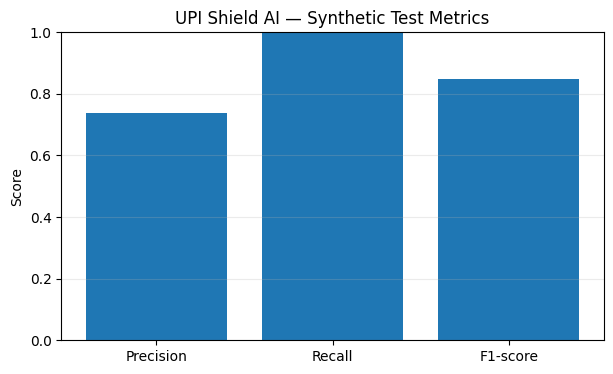

In [15]:
plt.figure(figsize=(7, 4))
plt.bar(metrics["Metric"], metrics["Score"])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("UPI Shield AI — Synthetic Test Metrics")
plt.grid(axis="y", alpha=0.25)
plt.show()

In [16]:
review_rows = []

for _, row in df.iterrows():
    result = detect_scam_pattern(
        row["amount"],
        row["typical_amount"],
        row["tx_count_10m"],
        bool(row["new_payee"])
    )

    if result["risk_level"] in ["MEDIUM", "HIGH"]:
        review_rows.append({
            "transaction_id": row["transaction_id"],
            "amount": row["amount"],
            "risk_score": result["risk_score"],
            "risk_level": result["risk_level"],
            "tx_count_10m": row["tx_count_10m"],
            "new_payee": bool(row["new_payee"]),
            "reasons": "; ".join(result["reasons"]),
            "synthetic_label": row["label"]
        })

review_df = pd.DataFrame(review_rows)

print("Events requiring demo review:", len(review_df))
display(review_df.head(15))

Events requiring demo review: 138


,transaction_id,amount,risk_score,risk_level,tx_count_10m,new_payee,reasons,synthetic_label
0,TX-0001,10409.00,80,HIGH,8,False,Rapid activity: 8 transactions in 10 minutes; ...,1
1,TX-0002,2678.33,30,MEDIUM,3,True,Elevated activity: 3 transactions in 10 minute...,0
2,TX-0003,2446.79,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
3,TX-0005,1164.30,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
4,TX-0008,821.09,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
5,TX-0009,1750.33,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
6,TX-0011,28071.00,90,HIGH,9,True,Rapid activity: 9 transactions in 10 minutes; ...,1
7,TX-0012,1463.33,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
8,TX-0016,2105.62,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0
9,TX-0017,1442.71,20,MEDIUM,3,False,Elevated activity: 3 transactions in 10 minutes,0


In [17]:
from google.colab import files

report_path = "upi_shield_ai_review_report.csv"
review_df.to_csv(report_path, index=False)

print("Report created:", report_path)
files.download(report_path)

Report created: upi_shield_ai_review_report.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import gradio as gr
import pandas as pd
import tempfile
import os

def get_dashboard_report():
    return review_df.copy()

def download_report():
    temp = tempfile.NamedTemporaryFile(
        mode="w", suffix=".csv", delete=False,
        encoding="utf-8", newline=""
    )
    temp.close()
    review_df.to_csv(temp.name, index=False)
    return temp.name

with gr.Blocks(title="UPI Shield AI — Security Console") as dashboard:
    gr.Markdown("# 🛡️ UPI Shield AI")
    gr.Markdown(
        "Explainable scam-pattern recognition | Synthetic data prototype"
    )

    gr.Markdown("## ML model evaluation")
    gr.Dataframe(
        value=metrics.round(3),
        label="Held-out synthetic test metrics",
        interactive=False
    )

    with gr.Row():
        gr.Number(
            value=float(metrics.loc[
                metrics["Metric"] == "Precision", "Score"
            ].iloc[0]),
            label="Precision"
        )
        gr.Number(
            value=float(metrics.loc[
                metrics["Metric"] == "Recall", "Score"
            ].iloc[0]),
            label="Recall"
        )
        gr.Number(
            value=float(metrics.loc[
                metrics["Metric"] == "F1-score", "Score"
            ].iloc[0]),
            label="F1-score"
        )

    gr.Markdown("## Analyst review queue")
    gr.Markdown(
        "These events are flagged by demo rules for human review; "
        "they are not confirmed scams."
    )
    gr.Dataframe(
        value=get_dashboard_report(),
        label="Review events",
        interactive=False
    )

    download_btn = gr.Button("Download review CSV")
    download_file = gr.File(label="CSV report")
    download_btn.click(
        fn=download_report,
        inputs=[],
        outputs=download_file
    )

    gr.Markdown(
        "**Safety:** Synthetic data only. No real payment connection, "
        "no automatic blocking. Metrics do not establish real-world "
        "fraud detection performance."
    )

dashboard.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b34f80289700be85ba.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, ml_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn) if (fp + tn) else 0

print("🛡️ UPI Shield AI — Error Analysis")
print("--------------------------------")
print("Correctly unflagged normal events:", tn)
print("False alarms:", fp)
print("Missed synthetic suspicious events:", fn)
print("Detected synthetic suspicious events:", tp)
print("False-positive rate:", round(fpr * 100, 2), "%")

error_report = X_test.copy()
error_report["actual_label"] = y_test
error_report["predicted_anomaly"] = ml_pred

print("\nFalse-positive examples:")
display(
    error_report[
        (error_report["actual_label"] == 0) &
        (error_report["predicted_anomaly"] == 1)
    ].head(10)
)

🛡️ UPI Shield AI — Error Analysis
--------------------------------
Correctly unflagged normal events: 71
False alarms: 5
Missed synthetic suspicious events: 0
Detected synthetic suspicious events: 14
False-positive rate: 6.58 %

False-positive examples:


,amount,amount_ratio,tx_count_10m,new_payee,actual_label,predicted_anomaly
106,274.61,0.385147,1,0,0,1
275,3331.23,1.222919,1,1,0,1
241,160.78,0.102342,2,0,0,1
71,5627.17,1.492618,1,1,0,1
226,216.34,0.155528,1,0,0,1


,Method,Precision,Recall,F1-score
0,Rule-based,1.000,1.0,1.000
1,Isolation Forest,0.737,1.0,0.848


<Axes: title={'center': 'Rules vs ML — Synthetic Test Results'}, xlabel='Method'>

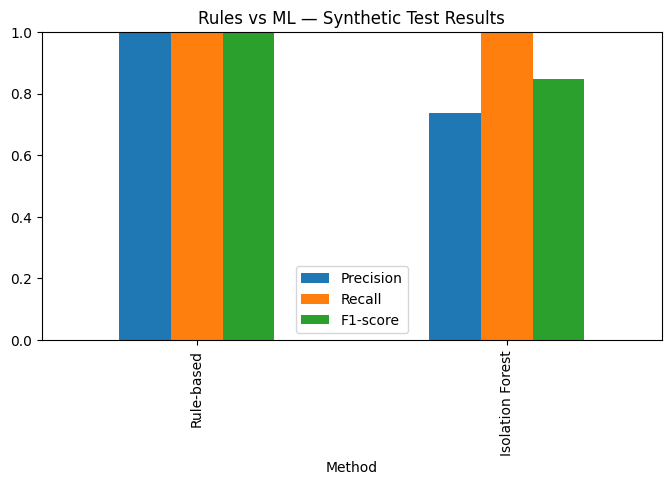

In [20]:
comparison = pd.DataFrame([
    {
        "Method": "Rule-based",
        "Precision": precision_score(y_test, rule_pred, zero_division=0),
        "Recall": recall_score(y_test, rule_pred, zero_division=0),
        "F1-score": f1_score(y_test, rule_pred, zero_division=0)
    },
    {
        "Method": "Isolation Forest",
        "Precision": precision_score(y_test, ml_pred, zero_division=0),
        "Recall": recall_score(y_test, ml_pred, zero_division=0),
        "F1-score": f1_score(y_test, ml_pred, zero_division=0)
    }
])

display(comparison.round(3))

comparison.set_index("Method").plot(
    kind="bar",
    ylim=(0, 1),
    figsize=(8, 4),
    title="Rules vs ML — Synthetic Test Results"
)

In [21]:
def hybrid_detection(amount, typical_amount, tx_count_10m, new_payee):
    # Rule-based explanation
    rule_result = detect_scam_pattern(
        amount,
        typical_amount,
        tx_count_10m,
        new_payee
    )

    # ML anomaly result
    sample = pd.DataFrame([{
        "amount": float(amount),
        "amount_ratio": float(amount) / max(float(typical_amount), 1),
        "tx_count_10m": int(tx_count_10m),
        "new_payee": int(bool(new_payee))
    }])

    ml_anomaly = int(model.predict(sample)[0] == -1)

    # Conservative alert logic:
    # HIGH requires strong rule-based evidence.
    if rule_result["risk_level"] == "HIGH":
        final_risk = "HIGH"
    elif rule_result["risk_level"] == "MEDIUM" or ml_anomaly:
        final_risk = "MEDIUM"
    else:
        final_risk = "LOW"

    return {
        "rule_score": rule_result["risk_score"],
        "rule_risk": rule_result["risk_level"],
        "ml_anomaly": ml_anomaly,
        "final_risk": final_risk,
        "reasons": rule_result["reasons"]
    }


# Test cases
test_cases = [
    (800, 1000, 1, False),
    (1000, 1000, 1, True),
    (15000, 1500, 7, True)
]

for case in test_cases:
    print("\nInput:", case)
    print(hybrid_detection(*case))


Input: (800, 1000, 1, False)
{'rule_score': 0, 'rule_risk': 'LOW', 'ml_anomaly': 0, 'final_risk': 'LOW', 'reasons': []}

Input: (1000, 1000, 1, True)
{'rule_score': 10, 'rule_risk': 'LOW', 'ml_anomaly': 0, 'final_risk': 'LOW', 'reasons': ['New payee: verify recipient details']}

Input: (15000, 1500, 7, True)
{'rule_score': 90, 'rule_risk': 'HIGH', 'ml_anomaly': 1, 'final_risk': 'HIGH', 'reasons': ['Rapid activity: 7 transactions in 10 minutes', 'Amount is 10.0x the typical amount', 'New payee: verify recipient details']}


In [23]:
def run_security_tests():
    tests = []

    # Test 1: New payee alone must not become HIGH
    r = hybrid_detection(1000, 1000, 1, True)
    tests.append(("New payee alone is not HIGH",
                  r["rule_risk"] != "HIGH"))

    # Test 2: High velocity and unusual amount should trigger HIGH
    r = hybrid_detection(15000, 1500, 7, True)
    tests.append(("Suspicious burst triggers HIGH",
                  r["final_risk"] == "HIGH"))

    # Test 3: Extreme values cannot exceed score bounds
    r = detect_scam_pattern(200000, 100, 12, True)
    tests.append(("Risk score stays within 0-100",
                  0 <= r["risk_score"] <= 100))

    # Test 4: No payment action is performed by the engine
    tests.append(("Detection returns assessment only",
                  "final_risk" in hybrid_detection(800, 1000, 1, False)))

    # Display results
    for name, passed in tests:
        print(("✅ PASS" if passed else "❌ FAIL"), "-", name)

    assert all(passed for _, passed in tests), "Fix failed tests before submission"
    print("\nAll security baseline tests passed!")

run_security_tests()

✅ PASS - New payee alone is not HIGH
✅ PASS - Suspicious burst triggers HIGH
✅ PASS - Risk score stays within 0-100
✅ PASS - Detection returns assessment only

All security baseline tests passed!


In [24]:
from sklearn.metrics import confusion_matrix
from datetime import datetime, timezone
import json

# ML metrics from the existing held-out test set
cm = confusion_matrix(y_test, ml_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

final_report = {
    "project": "UPI Shield AI",
    "report_generated_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_type": "Synthetic demonstration data",
    "test_samples": int(len(y_test)),
    "ml_precision": round(
        precision_score(y_test, ml_pred, zero_division=0), 4
    ),
    "ml_recall": round(
        recall_score(y_test, ml_pred, zero_division=0), 4
    ),
    "ml_f1_score": round(
        f1_score(y_test, ml_pred, zero_division=0), 4
    ),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
    "limitations": [
        "Synthetic data is not representative proof of real-world fraud detection.",
        "An anomaly is not necessarily a scam.",
        "No live UPI integration or automatic payment blocking."
    ]
}

with open("upi_shield_ai_evaluation.json", "w") as f:
    json.dump(final_report, f, indent=2)

print(json.dumps(final_report, indent=2))

{
  "project": "UPI Shield AI",
  "report_generated_utc": "2026-10-12T15:24:38.412560+00:00",
  "dataset_type": "Synthetic demonstration data",
  "test_samples": 90,
  "ml_precision": 0.7368,
  "ml_recall": 1.0,
  "ml_f1_score": 0.8485,
  "true_negatives": 71,
  "false_positives": 5,
  "false_negatives": 0,
  "true_positives": 14,
  "limitations": [
    "Synthetic data is not representative proof of real-world fraud detection.",
    "An anomaly is not necessarily a scam.",
    "No live UPI integration or automatic payment blocking."
  ]
}


In [25]:
from google.colab import files

comparison.to_csv("upi_shield_ai_model_comparison.csv", index=False)
review_df.to_csv("upi_shield_ai_review_queue.csv", index=False)

files.download("upi_shield_ai_evaluation.json")
files.download("upi_shield_ai_model_comparison.csv")
files.download("upi_shield_ai_review_queue.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from pathlib import Path
import zipfile

project = Path("/content/upi-shield-ai")
project.mkdir(exist_ok=True)

docs = {
    "README.md": """
# UPI Shield AI

Explainable scam-pattern recognition prototype for digital payment security.

## Problem
Suspicious transaction patterns can be difficult to identify quickly.
UPI Shield AI demonstrates how transparent rules and an anomaly-detection
model can help prioritize transactions for human review.

## Features
- Synthetic transaction dataset
- Explainable rule-based risk assessment
- Isolation Forest anomaly detection
- Rules-versus-ML evaluation
- Analyst review queue and CSV reports
- Interactive Gradio demo

## Technology
Python, Pandas, NumPy, scikit-learn, Matplotlib, Gradio.

## Run in Google Colab
Open the project notebook and run the cells in order.
The notebook creates synthetic data, trains the model, evaluates it,
and launches the interactive demo.

## Evaluation
Record precision, recall, F1-score, confusion matrix, and false-positive
rate from the held-out synthetic test set. Include the test size and
dataset-generation method with every reported result.

## Safety and limitations
- Synthetic data only; no live UPI or bank integration.
- An anomaly is not proof of fraud.
- The risk score is not a calibrated fraud probability.
- No automatic payment blocking or initiation.
- Synthetic results do not establish real-world performance.
- Do not upload credentials, payment PINs, or personal customer data.

## Team
Add team members, institution, contributions, and contact details here.
""",
    "THREAT_MODEL.md": """
# UPI Shield AI — Threat Model

## Assets to protect
- Transaction data and user privacy
- Model and detection rules
- Review reports and evaluation results
- Integrity of the demo and repository

## Threats
1. Sensitive information accidentally entered into a demo.
2. False positives that flag legitimate activity.
3. False negatives that miss suspicious activity.
4. Manipulated inputs designed to evade detection.
5. Misleading claims based on synthetic test results.
6. Unauthorized access to any future hosted service.

## Safeguards in this prototype
- Synthetic data only.
- No payment-network credentials or payment actions.
- Input checks and bounded demo risk score.
- Human review recommendation instead of automatic blocking.
- Separate reporting of rules and ML outputs.
- Clear documentation of dataset and model limitations.

## Future production requirements
- Authorized representative datasets and privacy/legal review.
- Authentication, authorization, and secure audit logging.
- Rate limiting, input validation, and monitoring.
- Robust adversarial testing and model drift monitoring.
- Independent evaluation and human escalation procedures.
""",
    "ARCHITECTURE.md": """
# Architecture

1. Synthetic transaction generator
2. Feature engineering: amount ratio, recent transaction count,
   and new-payee indicator
3. Transparent rule-based detector
4. Isolation Forest anomaly detector
5. Risk assessment and human-readable explanations
6. Gradio interface and analyst review queue
7. Held-out evaluation and CSV/JSON reports

## Data flow
Synthetic events -> Feature engineering -> Rules + ML
-> Risk explanation -> Human review -> Evaluation report

No live UPI connection, payment execution, or automatic blocking exists.
""",
    "DEMO_SCRIPT.md": """
# Two-minute demo script

## 0:00–0:20 — Problem
Explain that suspicious payment patterns need timely review, while
legitimate transactions must not be treated as confirmed fraud.

## 0:20–0:45 — Normal scenario
Enter a normal synthetic transaction and show the rule-based assessment.

## 0:45–1:10 — Suspicious scenario
Enter a high-amount, rapid-transaction scenario. Show the risk score,
evidence, and ML anomaly result.

## 1:10–1:30 — Explainability
Explain which features contributed to the alert and why new payee alone
is treated as a weak signal.

## 1:30–1:50 — Evaluation
Show the held-out synthetic test metrics, confusion matrix, and
false-positive rate. State dataset limitations clearly.

## 1:50–2:00 — Safety and impact
Explain that the system prioritizes human review and does not connect
to UPI or automatically block payments.
"""
}

for name, content in docs.items():
    (project / name).write_text(content.strip() + "\n", encoding="utf-8")

zip_name = "/content/upi_shield_ai_docs.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in project.rglob("*"):
        if path.is_file():
            archive.write(path, path.relative_to(project.parent))

print("Created documentation files:")
for name in docs:
    print("✅", name)
print("ZIP:", zip_name)

Created documentation files:
✅ README.md
✅ THREAT_MODEL.md
✅ ARCHITECTURE.md
✅ DEMO_SCRIPT.md
ZIP: /content/upi_shield_ai_docs.zip


In [27]:
from google.colab import files
files.download("/content/upi_shield_ai_docs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>